# 02 — Exploratory Data Analysis

**Project:** Learning the Path of the Storm — 24-hour tropical cyclone track forecasting
**Author:** Yatharth Vardan · AAI-590 Capstone, University of San Diego

**Rubric section:** Exploratory Data Analysis

With a clean table of storm tracks in hand from notebook 01, it is time to get to know the data. Everything
here is explored with one question in mind: *given a storm's last 24 hours of track (4 six-hourly fixes),
where will it be 24 hours from now?*

So rather than describing every column for its own sake, each section asks something that matters for that
forecast and closes with a short **Takeaway** on what the answer means for the models built next.

| | |
|---|---|
| **Input** | `data/processed/tracks_clean.csv.gz` (from `01_data_cleaning.ipynb`) |
| **Output** | Figures `reports/figures/fig02_*.png` – `fig10_*.png`, and `data/processed/eda_baselines.csv` |

Here are the questions, in order:

1. How much data is there, and how is it spread across basins, seasons and splits?
2. Where do storms go?
3. How fast and in which direction do they move, and does that depend on latitude?
4. How persistent is storm motion from one 6-hour step to the next?
5. What do intensity (wind, pressure) and its missing values look like?
6. How far does a storm move in 24 hours, and how well do naive forecasts do?
7. Do the train, validation and test splits look alike?

### Setting things up

First, the usual imports. Along with them come two project helpers: `load_clean()` to read the cleaned
table, and the great-circle distance and longitude-wrapping functions from `geo`. We also fix a color for
each basin so it looks the same in every figure, and define a small `savefig()` that writes each figure to
`reports/figures/` for the final report.

In [1]:
# Imports and paths
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root and make the project's helpers in src/ importable.
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from stormtrack.data_io import load_clean, PROCESSED   # project helpers
from stormtrack.geo import haversine_km, wrap_lon

# Where figures go, wider pandas printouts, and one plotting style for every figure.
FIG_DIR = ROOT / "reports" / "figures"
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

# Basin codes, readable names, a fixed order and one color per basin, reused in every figure.
BASIN_NAMES = {"WP": "Western Pacific", "SI": "South Indian", "EP": "Eastern Pacific",
               "NA": "North Atlantic", "SP": "South Pacific", "NI": "North Indian", "SA": "South Atlantic"}
BASIN_ORDER = ["WP", "SI", "EP", "NA", "SP", "NI", "SA"]
BASIN_COLORS = dict(zip(BASIN_ORDER, ["#2F6DB3", "#E07B39", "#3A9E6F", "#C9453B",
                                      "#8064A2", "#B8860B", "#555555"]))
SPLITS = ["train", "val", "test"]

# Save a figure into reports/figures and report where it went.
def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/figures/{name}")

## 1. Load the clean data

Let's start by reading in the table from notebook 01. There is one trap here worth pointing out. The North
Atlantic basin code is the text `"NA"`, and pandas reads `"NA"` as a missing value by default. Left alone,
that would quietly erase every Atlantic storm. So `load_clean()` turns that behavior off, and the `assert`
below double-checks that no basin codes went missing.

In [2]:
# Load the cleaned table from notebook 01. load_clean() keeps the basin code "NA" as text,
# and the assert below guards against Atlantic storms silently becoming missing values.
df = load_clean()
print(f"Fixes: {len(df):,}   segments: {df['SEG_ID'].nunique():,}   storms: {df['SID'].nunique():,}   "
      f"seasons: {df['SEASON'].min()}-{df['SEASON'].max()}")
assert df["BASIN"].notna().all(), "basin code 'NA' was read as missing"
df.head()

Fixes: 105,747   segments: 4,162   storms: 4,021   seasons: 1980-2024


,SID,SEG_ID,SEASON,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,wind_kt,wind_src,pres_mb,USA_SSHS,DIST2LAND,LANDFALL,USA_ATCF_ID,step_km,speed_kmh,heading_deg,dx_km,dy_km,dwind_kt,split
0,1980001S13173,1980001S13173_1,1980,SP,MM,PENI,1980-01-01 00:00:00,TS,-12.5,172.5,25.0,usa_1min,NaN,-1,647,647.0,SH051980,NaN,NaN,NaN,NaN,NaN,NaN,train
1,1980001S13173,1980001S13173_1,1980,SP,MM,PENI,1980-01-01 06:00:00,TS,-11.9,172.4,25.0,usa_1min,NaN,-1,670,670.0,SH051980,67.596394,11.266066,350.737028,-10.880594,66.342,0.0,train
2,1980001S13173,1980001S13173_1,1980,SP,MM,PENI,1980-01-01 12:00:00,TS,-11.5,172.5,25.0,usa_1min,NaN,-1,703,703.0,SH051980,45.791352,7.631892,13.765968,10.900708,44.228,0.0,train
3,1980001S13173,1980001S13173_1,1980,SP,MM,PENI,1980-01-01 18:00:00,TS,-11.2,172.7,30.0,usa_1min,NaN,-1,741,741.0,SH051980,39.852278,6.642046,33.189526,21.828589,33.171,5.0,train
4,1980001S13173,1980001S13173_1,1980,SP,MM,PENI,1980-01-02 00:00:00,TS,-11.2,173.0,30.0,usa_1min,997.0,-1,767,767.0,SH051980,32.723170,5.453862,90.029135,32.759978,0.000,0.0,train


That's 105,747 fixes in 4,162 continuous segments from 4,021 storms, the same counts notebook 01 ended
with, so nothing was lost on the way in.

Next, a quick overview of every column: its type, the share of missing values, and a numeric summary of
the main measurements.

In [3]:
# Column overview: type, share missing, and a quick numeric summary
num_cols = ["LAT", "LON", "wind_kt", "pres_mb", "DIST2LAND", "step_km", "speed_kmh", "heading_deg", "dwind_kt"]
overview = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing_%": (df.isna().mean() * 100).round(1)})
display(overview.T)
df[num_cols].describe().T.round(1)

,SID,SEG_ID,SEASON,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,wind_kt,wind_src,pres_mb,USA_SSHS,DIST2LAND,LANDFALL,USA_ATCF_ID,step_km,speed_kmh,heading_deg,dx_km,dy_km,dwind_kt,split
dtype,str,str,int64,str,str,str,datetime64[us],str,float64,float64,float64,str,float64,int64,int64,float64,str,float64,float64,float64,float64,float64,float64,str
missing_%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.4,0.0,0.0,1.2,4.6,3.9,3.9,3.9,3.9,3.9,3.9,0.0


,count,mean,std,min,25%,50%,75%,max
LAT,105747.0,7.6,18.2,-50.0,-12.6,14.2,20.3,51.9
LON,105747.0,38.9,110.3,-180.0,-77.1,85.1,130.6,179.9
wind_kt,105747.0,51.5,27.9,10.0,30.0,45.0,65.0,185.0
pres_mb,92639.0,985.8,21.4,872.0,976.0,993.0,1001.0,1020.0
DIST2LAND,105747.0,817.5,699.0,0.0,241.0,617.0,1307.0,4843.0
step_km,101585.0,102.9,58.7,0.0,61.9,94.5,132.7,673.6
speed_kmh,101585.0,17.2,9.8,0.0,10.3,15.7,22.1,112.3
heading_deg,101585.0,220.4,101.4,0.0,146.1,264.7,294.3,358.8
dwind_kt,101585.0,0.3,6.3,-70.0,0.0,0.0,5.0,84.0


Only two things stand out. The motion columns (`step_km`, `speed_kmh`, `heading_deg`, `dx_km`, `dy_km`,
`dwind_kt`) are missing on about 4% of rows, but that is by design. The first fix of every segment has no
earlier fix to measure motion from, and 4,162 segments out of 105,747 rows is exactly that 3.9%.

So the only column with real gaps is **pressure, missing on 12.4% of fixes**, which we look at more
closely in Section 6.

## 2. How much data, and where?

Counting fixes is only half the story, because a fix is only useful for training if it can serve as a
forecast origin. That needs 4 fixes of history (the fix itself and the 3 before it) plus the fix 24 hours
later in the same segment. A segment with *n* fixes therefore yields *n* − 7 usable samples.

In the cell below, we flag every fix that qualifies (`is_origin`) and then count storms, fixes and usable
samples per basin.

In [4]:
# Usable 24-h forecast samples: fix i is a forecast origin if i >= 3 (4 fixes of history: i-3..i)
# and fix i+4 exists in the same continuous segment.
g = df.groupby("SEG_ID")
df["i"] = g.cumcount()
df["n"] = g["LAT"].transform("size")
df["is_origin"] = (df["i"] >= 3) & (df["i"] <= df["n"] - 5)

by_basin = (df.groupby("BASIN")
              .agg(storms=("SID", "nunique"), fixes=("SID", "size"), samples=("is_origin", "sum"))
              .reindex(BASIN_ORDER))
by_basin["share_%"] = (100 * by_basin["fixes"] / by_basin["fixes"].sum()).round(1)
by_basin.index = [f"{b} ({BASIN_NAMES[b]})" for b in by_basin.index]
by_basin.loc["Total"] = by_basin.sum(numeric_only=True).round(1)
# A storm that moves from one basin to another is counted in both, so the true storm total is smaller:
by_basin.loc["Total", "storms"] = df["SID"].nunique()
print(f"Storms that cross into another basin: {(df.groupby('SID')['BASIN'].nunique() > 1).sum()}")
by_basin.astype({"storms": int, "fixes": int, "samples": int})

Storms that cross into another basin: 120


,storms,fixes,samples,share_%
WP (Western Pacific),1190,31487,23123,29.8
SI (South Indian),798,23454,17647,22.2
EP (Eastern Pacific),806,19144,13627,18.1
NA (North Atlantic),622,15341,10889,14.5
SP (South Pacific),478,11794,8550,11.2
NI (North Indian),246,4515,2772,4.3
SA (South Atlantic),1,12,5,0.0
Total,4021,105747,76613,100.1


Looking at the table, the Western Pacific is clearly the busiest basin, with about 30% of all fixes, followed by the South
Indian and Eastern Pacific. The North Atlantic, the basin with the NHC benchmark, holds about 15%. The
South Atlantic has a single storm, which is too few to say anything about.

About 120 storms drift from one basin into another, so they get counted in both rows. That's why the
Total row uses the true number of distinct storms rather than adding up the column.

Now the same count, but by split:

In [5]:
# Size of each chronological split: seasons, storms, fixes and usable 24-h forecast samples.
by_split = (df.groupby("split")
              .agg(seasons=("SEASON", lambda s: f"{s.min()}-{s.max()}"), storms=("SID", "nunique"),
                   fixes=("SID", "size"), samples=("is_origin", "sum"))
              .reindex(SPLITS))
by_split

,seasons,storms,fixes,samples
split,,,,
train,1980-2016,3302,88941,65169
val,2017-2019,275,6757,4699
test,2020-2024,444,10049,6745


So we end up with 65,169 training samples, 4,699 for validation and 6,745 for testing. For a sequence model,
65 thousand examples is a comfortable amount, and the test set is large enough for a stable average error.

Next, how does activity vary from year to year? The cell below counts storms per season, stacks them by
basin, and marks the two split boundaries with dashed lines (Figure 2).

saved reports/figures/fig02_storms_per_season.png


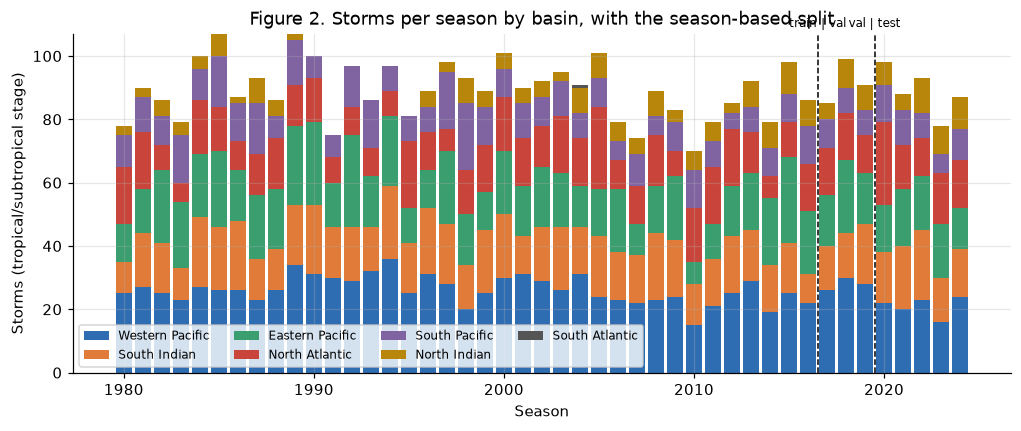

Storms per season: mean 89, min 70 (2010), max 107 (1985)


In [6]:
# Storms per season, stacked by basin
per_season = (df.drop_duplicates("SID").groupby(["SEASON", "BASIN"]).size()
                .unstack(fill_value=0).reindex(columns=BASIN_ORDER, fill_value=0))

fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(per_season))
for b in BASIN_ORDER:
    ax.bar(per_season.index, per_season[b], bottom=bottom, color=BASIN_COLORS[b], label=BASIN_NAMES[b], width=0.85)
    bottom += per_season[b].values
for x, lab in [(2016.5, "train | val"), (2019.5, "val | test")]:
    ax.axvline(x, color="k", ls="--", lw=1)
    ax.text(x, bottom.max() * 1.02, lab, ha="center", fontsize=8)
ax.set(xlabel="Season", ylabel="Storms (tropical/subtropical stage)",
       title="Figure 2. Storms per season by basin, with the season-based split")
ax.legend(ncol=4, fontsize=8, loc="lower left")
savefig(fig, "fig02_storms_per_season.png")
plt.show()
print(f"Storms per season: mean {per_season.sum(axis=1).mean():.0f}, "
      f"min {per_season.sum(axis=1).min()} ({per_season.sum(axis=1).idxmin()}), "
      f"max {per_season.sum(axis=1).max()} ({per_season.sum(axis=1).idxmax()})")

**Takeaway.** Activity is fairly steady, between 70 and 107 storms a season with an average of 89, so no
single year dominates the training data. The Western Pacific is the largest contributor almost every
year. Because the North Atlantic is only about 15% of the data, results later on will be reported both
overall and for the North Atlantic alone. That way they can be set against the NHC benchmark, which is
Atlantic-only.

## 3. Where do storms go?

Before looking at numbers, it helps to simply *see* the tracks. Here we draw every clean segment as a thin
line colored by basin (Figure 3).

No map library is used. Interestingly, the continents still show up quite clearly, simply as the places
storms never go. In the code, one small detail matters: when a track crosses the ±180° date line, the line
is broken at that point. Otherwise matplotlib would draw a stray line straight across the whole map.

saved reports/figures/fig03_track_map.png


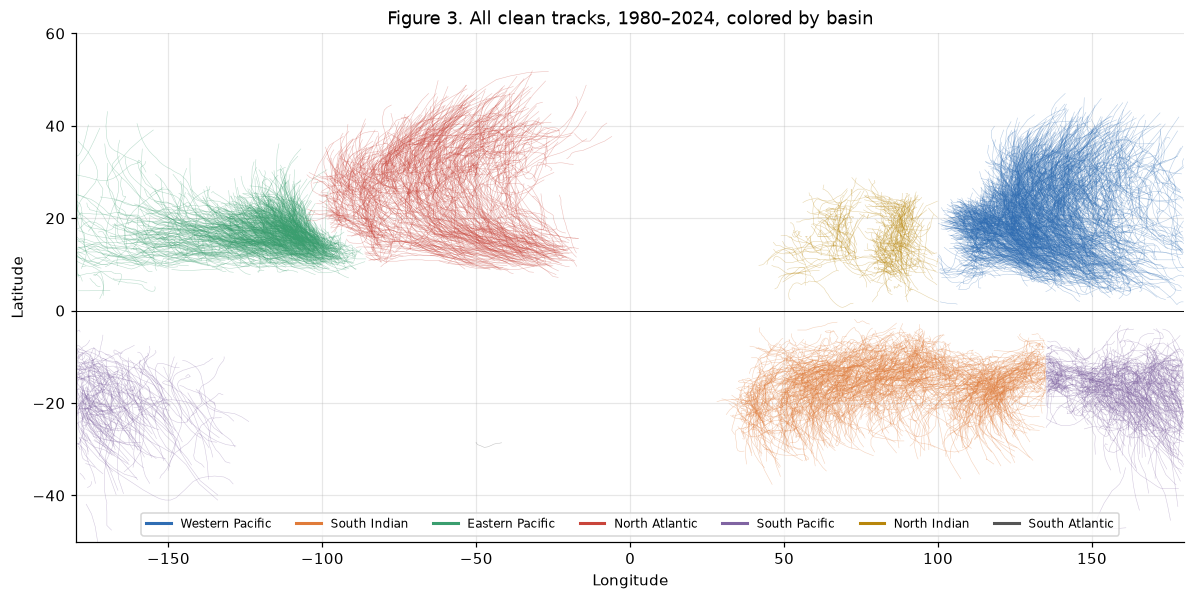

In [7]:
# Map every clean segment as a line, colored by basin, to show where the data come from.
fig, ax = plt.subplots(figsize=(13, 6))
for b in BASIN_ORDER:
    sub = df[df["BASIN"] == b]
    for _, seg in sub.groupby("SEG_ID"):
        lon = seg["LON"].to_numpy()
        # Break the line where a track crosses the date line so it is not drawn across the whole map
        lon = np.where(np.abs(np.diff(lon, prepend=lon[0])) > 180, np.nan, lon)
        ax.plot(lon, seg["LAT"], color=BASIN_COLORS[b], lw=0.35, alpha=0.35)
    ax.plot([], [], color=BASIN_COLORS[b], lw=2, label=BASIN_NAMES[b])
ax.axhline(0, color="k", lw=0.6)
ax.set(xlim=(-180, 180), ylim=(-50, 60), xlabel="Longitude", ylabel="Latitude",
       title="Figure 3. All clean tracks, 1980–2024, colored by basin")
ax.legend(ncol=7, fontsize=8, loc="lower center")
savefig(fig, "fig03_track_map.png")
plt.show()

**Takeaway.** A familiar pattern emerges. Storms form in the tropics, drift westward, and many then turn
toward the pole and swing back east, the classic "recurvature". Hardly any form within about 5° of the
equator, and the two hemispheres look like mirror images of each other. So for the model:

- **Latitude matters.** The same recent motion can lead to a very different next move depending on how
  far from the equator a storm is.
- **Hemisphere matters too.** "Poleward" means north in one hemisphere and south in the other, so latitude
  should go into the model with its sign rather than as an absolute value.
- **Longitude needs care.** Pacific tracks cross the date line, so the model should learn from
  *displacements* (km east and north) rather than raw longitudes, which jump from +180 to −180.

## 4. Speed and direction of motion

So far we have *where* storms go. Next comes *how* they move. Each fix carries the speed (`speed_kmh`) and
direction (`heading_deg`, 0° = north, 90° = east) of its last 6-hour step. In the cell below, we plot a
histogram of speed alongside a compass "rose" of headings for each hemisphere (Figure 4), and print the
speed percentiles.

saved reports/figures/fig04_speed_heading.png


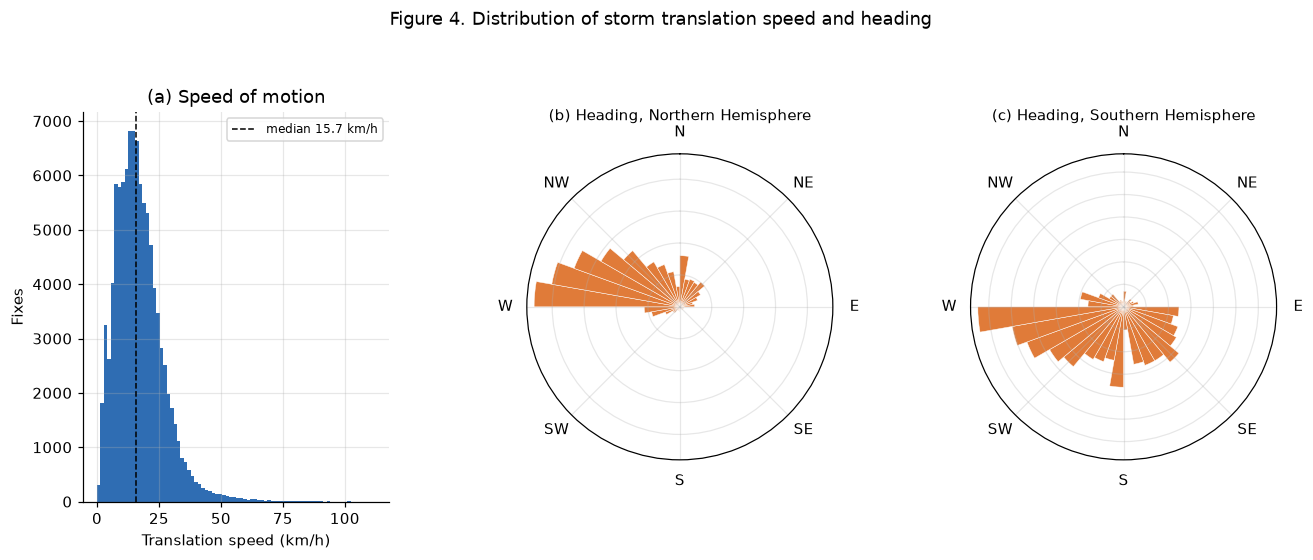

count    101585.0
mean         17.2
std           9.8
min           0.0
5%            4.1
25%          10.3
50%          15.7
75%          22.1
95%          34.1
max         112.3


In [8]:
# (a) How fast storms move: histogram of 6-hour translation speed, with the median marked.
# (b, c) Which way they move: heading roses, split by hemisphere because Southern Hemisphere
# storms curve the opposite way (poleward means south there).
fig = plt.figure(figsize=(14, 4.6))
fig.subplots_adjust(wspace=0.45)
ax1 = fig.add_subplot(1, 3, 1)
ax1.hist(df["speed_kmh"].dropna(), bins=80, color="#2F6DB3")
ax1.axvline(df["speed_kmh"].median(), color="k", ls="--", lw=1, label=f"median {df['speed_kmh'].median():.1f} km/h")
ax1.set(xlabel="Translation speed (km/h)", ylabel="Fixes", title="(a) Speed of motion")
ax1.legend(fontsize=8)

for k, (hemi, mask) in enumerate([("Northern", df["LAT"] > 0), ("Southern", df["LAT"] < 0)]):
    ax = fig.add_subplot(1, 3, 2 + k, projection="polar")
    h = np.radians(df.loc[mask, "heading_deg"].dropna())
    counts, edges = np.histogram(h, bins=36, range=(0, 2 * np.pi))
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color="#E07B39", edgecolor="w", lw=0.3)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_yticklabels([])
    ax.set_title(f"({'bc'[k]}) Heading, {hemi} Hemisphere", fontsize=10, pad=22)
    ax.set_thetagrids(range(0, 360, 45), ["N", "NE", "E", "SE", "S", "SW", "W", "NW"])
fig.suptitle("Figure 4. Distribution of storm translation speed and heading", y=1.08)
savefig(fig, "fig04_speed_heading.png")
plt.show()

# Speed percentiles, to quote typical and extreme values in the text.
print(df["speed_kmh"].describe(percentiles=[.05, .25, .5, .75, .95]).round(1).to_string())

In the Northern Hemisphere, most steps point west to northwest. In the Southern Hemisphere, they point west
to southwest, which is the same "westward and poleward" motion, mirrored.

But does motion change as storms move away from the equator? To find out, the next cell groups steps into
5° bands of distance from the equator and, for each band, works out the share of steps heading east, the
share heading poleward, and the median speed (Figure 5). Bands with fewer than 200 steps are left out,
since their numbers would be too noisy.

saved reports/figures/fig05_motion_by_latitude.png


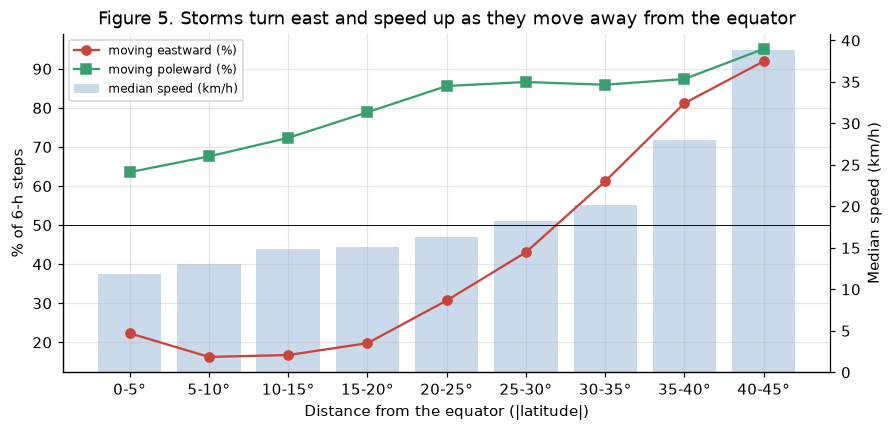

,fixes,median_speed_kmh,eastward_share,poleward_share
0-5°,354,11.86,0.22,0.64
5-10°,6350,13.01,0.16,0.68
10-15°,27435,14.87,0.17,0.72
15-20°,32673,15.05,0.20,0.79
20-25°,17794,16.32,0.31,0.86
25-30°,8752,18.28,0.43,0.87
30-35°,5182,20.10,0.61,0.86
35-40°,2295,28.03,0.81,0.87
40-45°,633,38.89,0.92,0.95


In [9]:
# How motion changes with latitude: speed and eastward share in 5-degree bands of |latitude|
m = df.dropna(subset=["speed_kmh"]).copy()
m["abs_lat_band"] = (m["LAT"].abs() // 5 * 5).astype(int)
m["poleward"] = np.sign(m["LAT"]) * m["dy_km"] > 0     # north in the NH, south in the SH
lat_tab = (m.groupby("abs_lat_band")
             .agg(fixes=("speed_kmh", "size"), median_speed_kmh=("speed_kmh", "median"),
                  eastward_share=("dx_km", lambda x: (x > 0).mean()),
                  poleward_share=("poleward", "mean"))
             .query("fixes >= 200"))
lat_tab.index = [f"{b}-{b+5}°" for b in lat_tab.index]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lat_tab.index, lat_tab["eastward_share"] * 100, "o-", color="#C9453B", label="moving eastward (%)")
ax.plot(lat_tab.index, lat_tab["poleward_share"] * 100, "s-", color="#3A9E6F", label="moving poleward (%)")
ax.set_ylabel("% of 6-h steps"); ax.set_xlabel("Distance from the equator (|latitude|)")
ax.axhline(50, color="k", lw=0.6)
ax2 = ax.twinx(); ax2.grid(False)
ax2.bar(lat_tab.index, lat_tab["median_speed_kmh"], color="#2F6DB3", alpha=0.25, label="median speed (km/h)")
ax2.set_ylabel("Median speed (km/h)")
ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
ax.set_title("Figure 5. Storms turn east and speed up as they move away from the equator")
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
savefig(fig, "fig05_motion_by_latitude.png")
plt.show()
lat_tab.round(2)

**Takeaway.** A typical storm moves at about 16 km/h (median; the mean is 17 km/h). The distribution has a
long right tail, though: 5% of steps are faster than 34 km/h, almost all of them away from the tropics.

Direction depends strongly on latitude:

- **5–20° from the equator:** only 16–20% of steps head east.
- **Past 30°:** the majority do, 61% at 30–35° and over 90% beyond 40°.
- **Speed:** median speed more than doubles over the same range, from about 15 km/h to about 39 km/h.
- **Poleward motion:** most steps at every latitude move poleward.

In other words, this is the nonlinear "recurvature" behavior. A storm that has been moving steadily west-northwest can
turn sharply and speed up, and a straight-line extrapolation cannot see that coming. That's the main reason
for trying models (XGBoost, LSTM/GRU) that can learn such turns from the recent track and the latitude.

## 5. How persistent is storm motion?

Here's another angle on the same question. If a storm's next move looked just like its last one, simple
extrapolation would already forecast well. To measure how much "memory" storm motion has, the code below
correlates each 6-hour displacement with the displacement *k* steps earlier in the same segment, for lags
from 6 to 72 hours (Figure 6). The shaded band marks the 24-hour history window the models will use.

saved reports/figures/fig06_motion_autocorrelation.png


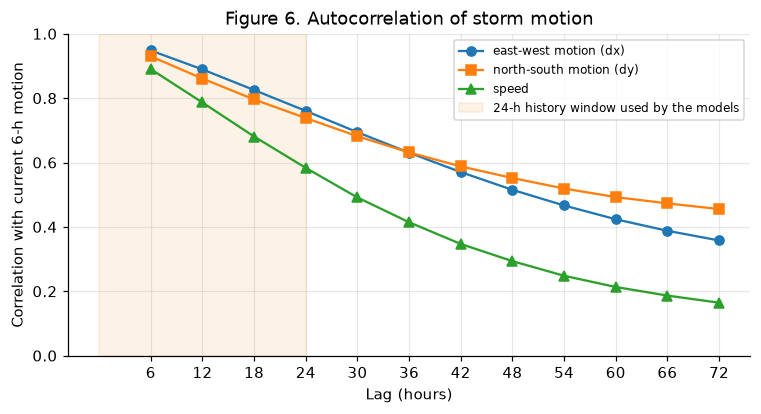

,lag_steps,corr_east_motion,corr_north_motion,corr_speed
lag_hours,,,,
6,1,0.948,0.930,0.890
12,2,0.889,0.861,0.787
18,3,0.825,0.796,0.681
24,4,0.760,0.738,0.583
30,5,0.694,0.682,0.491
36,6,0.631,0.631,0.414
42,7,0.570,0.588,0.347
48,8,0.515,0.552,0.294
54,9,0.467,0.519,0.248


In [10]:
# How long does motion stay predictable? Correlate each 6-hour motion (east-west, north-south,
# speed) with the motion 6 to 72 hours earlier in the same segment.
lags = range(1, 13)
rows = []
for k in lags:
    gx = df.groupby("SEG_ID")
    lag_dx, lag_dy = gx["dx_km"].shift(k), gx["dy_km"].shift(k)
    lag_sp = gx["speed_kmh"].shift(k)
    rows.append({"lag_steps": k, "lag_hours": 6 * k,
                 "corr_east_motion": df["dx_km"].corr(lag_dx),
                 "corr_north_motion": df["dy_km"].corr(lag_dy),
                 "corr_speed": df["speed_kmh"].corr(lag_sp)})
acf = pd.DataFrame(rows).set_index("lag_hours")

# Plot the three correlation curves; the shaded band is the history the baseline models use.
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(acf.index, acf["corr_east_motion"], "o-", label="east-west motion (dx)")
ax.plot(acf.index, acf["corr_north_motion"], "s-", label="north-south motion (dy)")
ax.plot(acf.index, acf["corr_speed"], "^-", label="speed")
ax.axvspan(0, 24, color="#F29C38", alpha=0.12, label="24-h history window used by the models")
ax.set(xlabel="Lag (hours)", ylabel="Correlation with current 6-h motion", ylim=(0, 1), xticks=list(acf.index),
       title="Figure 6. Autocorrelation of storm motion")
ax.legend(fontsize=8)
savefig(fig, "fig06_motion_autocorrelation.png")
plt.show()
acf.round(3)

**Takeaway.** Storm motion turns out to be highly persistent. The correlation with the previous step is
0.93–0.95 for the east and north components, and it fades only slowly: about 0.75 at 24 hours and still
about 0.4 at 72 hours. Speed is less persistent than direction (0.58 at 24 hours). Two design choices
follow from this:

- **Persistence is a strong baseline.** Any learned model has to beat simple extrapolation to be worth it.
- **A 24-hour (4-fix) history is a sensible window.** It captures most of the useful memory. Longer
  windows would add a little information but cost samples, because every segment would need more fixes
  before its first forecast. Window length gets revisited during tuning.

## 6. Intensity: wind, pressure and missing values

Intensity isn't what we are forecasting, but it may still help as an input, since stronger storms tend to
be steered by winds higher up in the atmosphere and can move differently from weak ones.

In the next cell, Figure 7 shows three things side by side: (a) the distribution of wind speeds, with the
tropical-storm and hurricane-category thresholds marked; (b) wind against central pressure, using a random
sample of 20,000 fixes so the plot stays readable; and (c) the share of fixes missing pressure in each
basin. Below the figure, we also print missing pressure by decade and where the wind values came from.

saved reports/figures/fig07_intensity.png


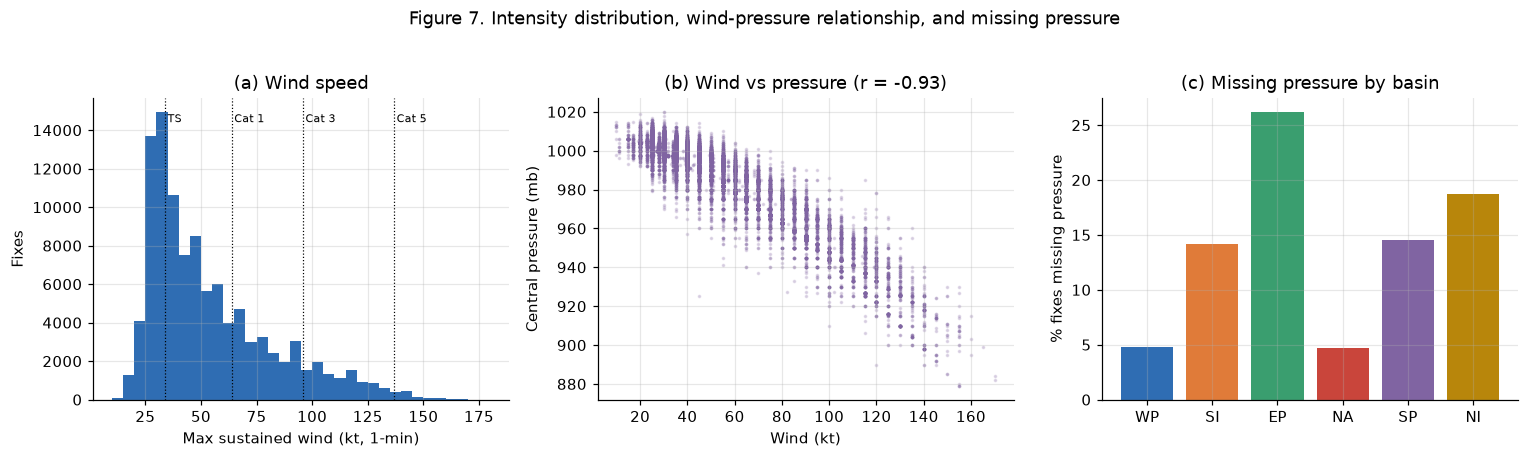

Missing pressure by decade (%): {1980: 33.2, 1990: 15.7, 2000: 2.3, 2010: 0.0, 2020: 0.0}
Wind source: {'usa_1min': 95.2, 'wmo_10min_converted': 4.7, 'missing': 0.2}


In [11]:
# Intensity: (a) wind distribution with Saffir-Simpson thresholds, (b) wind vs central pressure
# on a random sample of 20,000 fixes, (c) how often pressure is missing in each basin.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(df["wind_kt"], bins=np.arange(10, 185, 5), color="#2F6DB3")
for thr, lab in [(34, "TS"), (64, "Cat 1"), (96, "Cat 3"), (137, "Cat 5")]:
    axes[0].axvline(thr, color="k", ls=":", lw=0.8)
    axes[0].text(thr + 1, axes[0].get_ylim()[1] * 0.92, lab, fontsize=7)
axes[0].set(xlabel="Max sustained wind (kt, 1-min)", ylabel="Fixes", title="(a) Wind speed")

sample = df.dropna(subset=["pres_mb"]).sample(20000, random_state=0)
axes[1].scatter(sample["wind_kt"], sample["pres_mb"], s=2, alpha=0.2, color="#8064A2")
r = df[["wind_kt", "pres_mb"]].corr().iloc[0, 1]
axes[1].set(xlabel="Wind (kt)", ylabel="Central pressure (mb)", title=f"(b) Wind vs pressure (r = {r:.2f})")

# Share of fixes missing pressure, by basin and by decade (older records omit it more often).
miss = (df.groupby("BASIN")["pres_mb"].apply(lambda s: s.isna().mean() * 100)
          .reindex(BASIN_ORDER).drop("SA"))
miss_dec = df.assign(decade=df["SEASON"] // 10 * 10).groupby("decade")["pres_mb"].apply(lambda s: s.isna().mean() * 100)
axes[2].bar(miss.index, miss.values, color=[BASIN_COLORS[b] for b in miss.index])
axes[2].set(ylabel="% fixes missing pressure", title="(c) Missing pressure by basin")
fig.suptitle("Figure 7. Intensity distribution, wind-pressure relationship, and missing pressure", y=1.03)
fig.tight_layout()
savefig(fig, "fig07_intensity.png")
plt.show()
print("Missing pressure by decade (%):", miss_dec.round(1).to_dict())
print("Wind source:", df["wind_src"].value_counts(normalize=True).mul(100).round(1).to_dict())

**Takeaway.** Most fixes are at tropical-storm strength or weaker, with a long tail of intense storms.
Wind and pressure move almost in lockstep (r = −0.93), so they carry largely the same information.

Pressure is also the column with gaps, and those gaps are concentrated in two places:

- **Early decades:** about a third of fixes in the 1980s are missing pressure, and none since 2010.
- **Certain basins:** 26% in the Eastern Pacific, against under 5% in the Atlantic and Western Pacific.

So **wind is the intensity input of choice**. Pressure can be left out, or included with a "missing" flag,
without losing much.

## 7. The forecasting target and two naive forecasts

Now to the heart of the matter: how far does a storm actually move in 24 hours, and how good are the
simplest possible forecasts? Two naive forecasts set the bar every later model must clear:

- **No motion:** assume the storm stays put. Its error is simply the distance travelled in 24 hours.
- **Persistence:** assume the storm keeps its last 6-hour motion for four more steps (a straight-line
  extrapolation). It's the simplest member of the CLIPER family of baselines used in operational
  forecast verification.

Errors are great-circle distances in km, the same measure the National Hurricane Center uses. For
context, NHC's official 24-hour Atlantic track error averaged about **63 km over 2020–2024** (National
Hurricane Center, 2025). Those forecasts draw on full weather models and satellite data, so 63 km is a
reference point to compare against, not a number this project expects to match.

In the cell below, for every fix we look up the previous fix and the one 24 hours ahead. From those we
compute the 24-hour displacement (east and north components in km, plus total distance) and the error of
both naive forecasts. The summary covers only the usable forecast origins from Section 2.

In [12]:
gs = df.groupby("SEG_ID")
lat1, lon1 = gs["LAT"].shift(1), gs["LON"].shift(1)        # previous fix (6 h earlier)
lat24, lon24 = gs["LAT"].shift(-4), gs["LON"].shift(-4)    # fix 24 h later (target)

# 24-h displacement in km (local east/north components, using the start latitude)
KM_PER_DEG = 111.195
df["dy24_km"] = (lat24 - df["LAT"]) * KM_PER_DEG
df["dx24_km"] = wrap_lon(lon24 - df["LON"]) * KM_PER_DEG * np.cos(np.radians(df["LAT"]))
df["dist24_km"] = haversine_km(df["LAT"], df["LON"], lat24, lon24)

# Persistence: repeat the last 6-h step four more times
p_lat = df["LAT"] + 4 * (df["LAT"] - lat1)
p_lon = wrap_lon(df["LON"] + 4 * wrap_lon(df["LON"] - lon1))
df["err_nomotion_km"] = df["dist24_km"]
df["err_persist_km"] = haversine_km(p_lat, p_lon, lat24, lon24)

S = df[df["is_origin"]].copy()
print(f"Forecast samples: {len(S):,}")
S[["dx24_km", "dy24_km", "dist24_km", "err_persist_km"]].describe(percentiles=[.5, .9, .99]).round(1).T

Forecast samples: 76,613


,count,mean,std,min,50%,90%,99%,max
dx24_km,76613.0,-150.4,328.6,-1223.3,-190.8,277.6,821.7,2074.9
dy24_km,76613.0,71.8,255.4,-1389.9,77.8,378.1,754.8,1945.9
dist24_km,76613.0,394.6,208.4,0.0,370.3,656.0,1045.3,2351.5
err_persist_km,76613.0,164.0,118.2,0.0,136.3,312.6,582.7,1664.9


On average, a storm travels about 395 km in 24 hours. The mean east–west component is negative (−150 km),
which reflects the general westward drift, while the mean poleward component is positive.

Next, Figure 8 pictures both pieces: (a) the cloud of 24-hour displacements, with the north–south axis
flipped for the Southern Hemisphere so that "up" always means poleward, and (b) the error distributions of
the two naive forecasts, with NHC's 63 km mean marked for reference.

saved reports/figures/fig08_target_and_naive_errors.png


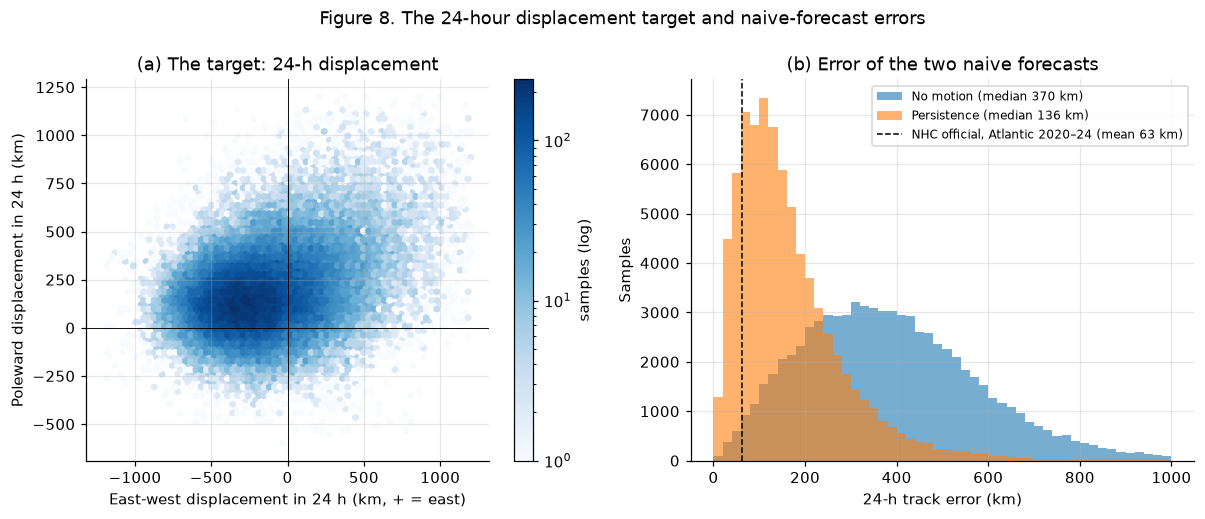

In [13]:
# (a) The forecasting target: 24-hour displacement, east-west against poleward (log color scale).
# (b) Error distributions of the two naive forecasts, with NHC's official error for reference.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
hb = axes[0].hexbin(S["dx24_km"], S["dy24_km"] * np.sign(S["LAT"]), gridsize=70, bins="log",
                    cmap="Blues", extent=(-1200, 1200, -600, 1200))
axes[0].axhline(0, color="k", lw=0.6); axes[0].axvline(0, color="k", lw=0.6)
axes[0].set(xlabel="East-west displacement in 24 h (km, + = east)",
            ylabel="Poleward displacement in 24 h (km)", title="(a) The target: 24-h displacement")
fig.colorbar(hb, ax=axes[0], label="samples (log)")

bins = np.arange(0, 1001, 20)
axes[1].hist(S["err_nomotion_km"], bins=bins, alpha=0.6, label=f"No motion (median {S['err_nomotion_km'].median():.0f} km)")
axes[1].hist(S["err_persist_km"], bins=bins, alpha=0.6, label=f"Persistence (median {S['err_persist_km'].median():.0f} km)")
axes[1].axvline(63, color="k", ls="--", lw=1, label="NHC official, Atlantic 2020–24 (mean 63 km)")
axes[1].set(xlabel="24-h track error (km)", ylabel="Samples", title="(b) Error of the two naive forecasts")
axes[1].legend(fontsize=8)
fig.suptitle("Figure 8. The 24-hour displacement target and naive-forecast errors", y=1.02)
savefig(fig, "fig08_target_and_naive_errors.png")
plt.show()

It's clear from panel (b) that persistence is in a different league from "no motion", although its long
right tail shows it can still miss badly.

So how do the two compare on each split? The next cell computes the mean and median errors per split, for
all basins and for the North Atlantic alone, and saves the table to `data/processed/eda_baselines.csv` so
the modeling notebooks can quote the same numbers.

In [14]:
# Naive-forecast errors by split, overall and North Atlantic only
def summarize(d):
    return pd.Series({"samples": len(d),
                      "no_motion_mean_km": d["err_nomotion_km"].mean(),
                      "persistence_mean_km": d["err_persist_km"].mean(),
                      "persistence_median_km": d["err_persist_km"].median()})

base = pd.concat({
    "All basins": S.groupby("split").apply(summarize, include_groups=False).reindex(SPLITS),
    "North Atlantic": S[S["BASIN"] == "NA"].groupby("split").apply(summarize, include_groups=False).reindex(SPLITS),
}).round(1)
base["samples"] = base["samples"].astype(int)
base.to_csv(PROCESSED / "eda_baselines.csv")
base

samples  no_motion_mean_km  persistence_mean_km  persistence_median_km
               split                                                                        
All basins     train    65169              394.4                163.3                  135.2
               val       4699              391.1                168.0                  139.2
               test      6745              398.6                167.8                  140.3
North Atlantic train     8687              471.8                191.5                  157.6
               val        801              461.6                182.9                  151.0
               test      1401              461.7                179.1                  147.8

Persistence comes in at about 168 km on the test seasons across all basins, and about 179 km for the North
Atlantic. The validation and test numbers are close to the training numbers, which is a first hint that
the splits behave similarly.

Where exactly does persistence go wrong? Section 4 suggested two suspects: high latitudes, where storms
recurve, and storms that are already turning. To test both, the next cell measures the change in heading
between the last two 6-hour steps (the "turning rate") and plots the mean persistence error by latitude
band and by turning rate (Figure 9).

saved reports/figures/fig09_persistence_error_drivers.png


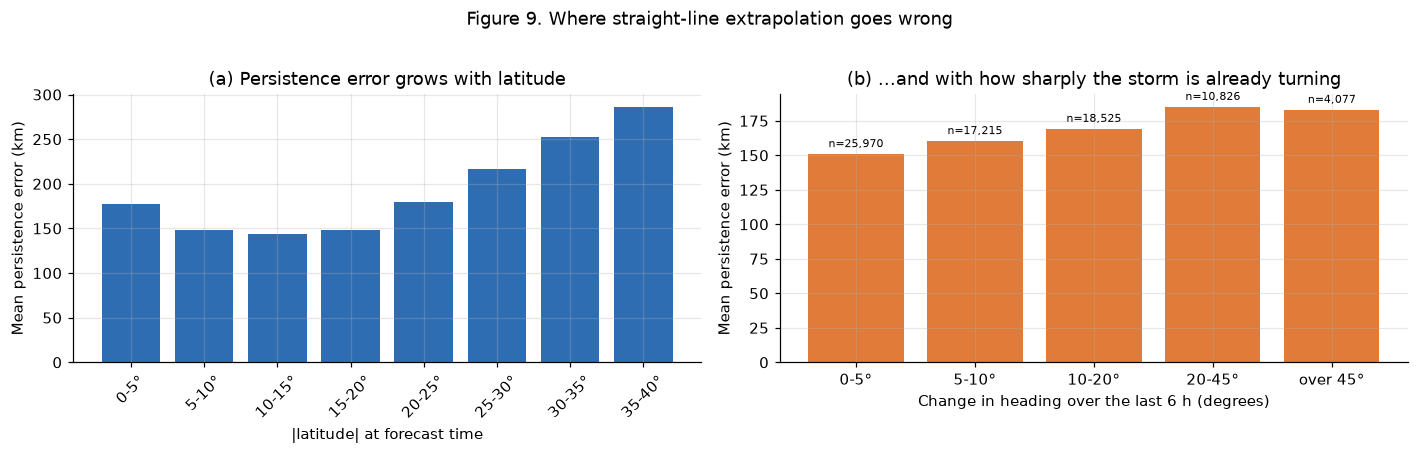

In [15]:
# Where does persistence fail? Error by latitude band and by how much the storm was already turning
S["abs_lat_band"] = (S["LAT"].abs() // 5 * 5).astype(int)
# How sharply the storm is already turning: change in heading between the last two 6-h steps
h_prev = df.groupby("SEG_ID")["heading_deg"].shift(1)
df["turn_deg"] = np.abs((df["heading_deg"] - h_prev + 180) % 360 - 180)
S["turn_deg"] = df.loc[S.index, "turn_deg"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lat_err = S.groupby("abs_lat_band")["err_persist_km"].agg(["mean", "size"]).query("size >= 200")
axes[0].bar([f"{b}-{b+5}°" for b in lat_err.index], lat_err["mean"], color="#2F6DB3")
axes[0].set(xlabel="|latitude| at forecast time", ylabel="Mean persistence error (km)",
            title="(a) Persistence error grows with latitude")
axes[0].tick_params(axis="x", rotation=45)

S["turn_bin"] = pd.cut(S["turn_deg"], [0, 5, 10, 20, 45, 180], include_lowest=True,
                       labels=["0-5°", "5-10°", "10-20°", "20-45°", "over 45°"])
turn_err = S.groupby("turn_bin", observed=True)["err_persist_km"].agg(["mean", "size"])
axes[1].bar(turn_err.index.astype(str), turn_err["mean"], color="#E07B39")
for x, (mn, n) in enumerate(turn_err.values):
    axes[1].text(x, mn + 5, f"n={int(n):,}", ha="center", fontsize=7)
axes[1].set(xlabel="Change in heading over the last 6 h (degrees)", ylabel="Mean persistence error (km)",
            title="(b) ...and with how sharply the storm is already turning")
fig.suptitle("Figure 9. Where straight-line extrapolation goes wrong", y=1.02)
fig.tight_layout()
savefig(fig, "fig09_persistence_error_drivers.png")
plt.show()

**Takeaway.** Both suspects are confirmed:

- **Latitude:** away from the tropics, where storms recurve and speed up, persistence error roughly
  doubles, from about 145 km between 5° and 20° to 250–285 km beyond 30°.
- **Turning:** when a storm is already turning, the error also rises, more modestly, from about 150 km for
  steady storms to about 185 km.

Overall, persistence cuts the no-motion error by more than half (about 395 km down to about 165 km), but it
is still nearly three times NHC's 63 km. The cases where it struggles are exactly where a learned model
has room to add value. They also give a natural way to break down model errors in the analysis notebook.

## 8. Do the splits look alike?

One last check before modeling. Because we split by season, the test set is effectively "the future"
relative to training. That's realistic, but it can bring distribution shift if recent seasons differ from
older ones, for example through changes in how storms are observed or which basins were active.

So in this final cell, Figure 10 compares the three splits on basin mix, translation speed and wind, and
the table underneath lists their medians.

saved reports/figures/fig10_split_comparison.png


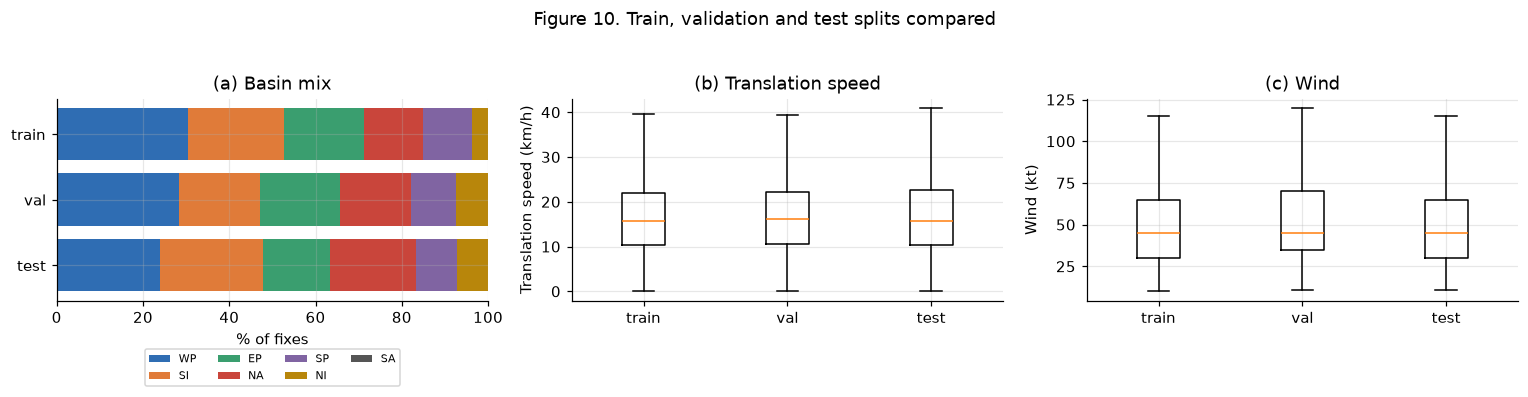

,LAT,speed_kmh,wind_kt,dist24_km,abs_lat_median
split,,,,,
train,14.0,15.7,45.0,367.7,17.0
val,15.1,16.1,45.0,369.3,17.5
test,14.9,15.7,45.0,368.2,17.7


In [16]:
# Are the train, validation and test seasons alike? Compare (a) the basin mix,
# (b) translation speed and (c) wind across the three splits.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
mix = (pd.crosstab(df["split"], df["BASIN"], normalize="index") * 100).reindex(SPLITS)[BASIN_ORDER]
left = np.zeros(len(mix))
for b in BASIN_ORDER:
    axes[0].barh(mix.index, mix[b], left=left, color=BASIN_COLORS[b], label=b)
    left += mix[b].values
axes[0].invert_yaxis(); axes[0].set(xlabel="% of fixes", title="(a) Basin mix")
axes[0].legend(ncol=4, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, -0.45))

for ax, col, lab in [(axes[1], "speed_kmh", "Translation speed (km/h)"), (axes[2], "wind_kt", "Wind (kt)")]:
    data = [df.loc[df["split"] == s, col].dropna() for s in SPLITS]
    ax.boxplot(data, tick_labels=SPLITS, showfliers=False)
    ax.set(ylabel=lab, title=f"({'bc'[axes.tolist().index(ax) - 1]}) {lab.split(' (')[0]}")
fig.suptitle("Figure 10. Train, validation and test splits compared", y=1.03)
fig.tight_layout()
savefig(fig, "fig10_split_comparison.png")
plt.show()

# Medians per split, to check numerically for any shift between the periods.
shift = df.groupby("split")[["LAT", "speed_kmh", "wind_kt", "dist24_km"]].median().reindex(SPLITS)
shift["abs_lat_median"] = df.assign(a=df["LAT"].abs()).groupby("split")["a"].median()
shift.round(1)

**Takeaway.** Speed, intensity and latitude are almost identical across the three splits (median speed
15.7–16.1 km/h, median wind 45 kt). The basin mix, however, does shift. The test seasons have fewer
Western Pacific fixes (24% versus 30.5% in training) and more North Atlantic (20% versus 14%) and North
Indian (7% versus 4%) fixes.

Since the North Atlantic has the highest persistence error of the large basins, this shift makes the test
set slightly harder than the training mix. That's one more reason to report per-basin errors rather than a
single overall number: any change in error between validation and test can then be traced back to the
basin mix.

## 9. Summary: what the EDA means for modeling

To wrap up, here is each finding next to the modeling decision it leads to.

| Finding | Modeling decision |
|---|---|
| 105,747 clean fixes, 76,613 usable 24-h samples; WP largest, SA negligible | Train one global model on all basins; report errors overall and for the North Atlantic |
| Motion is highly persistent (lag-1 correlation 0.93–0.95) | Persistence is the first baseline (mean test error ~168 km); learned models must beat it |
| Memory fades slowly over 24 h | Use a 4-fix (24-h) history window; test longer windows during tuning |
| Direction and speed depend strongly on latitude (recurvature) | Give the model signed latitude; this nonlinearity is what XGBoost/LSTM/GRU should learn |
| Tracks cross the date line | Use east/north displacements in km as inputs and targets, not raw longitudes |
| Persistence error grows with latitude and turning rate | Break down model errors by these factors in the analysis |
| Wind and pressure strongly correlated; pressure has gaps | Use wind as the intensity input; pressure optional with a missing flag |
| Splits match on speed and intensity; test has more Atlantic, less W. Pacific; validation is small | Keep the season-based split; report per-basin errors; avoid over-tuning on validation |

All exact counts and baseline errors appear in the cells above, and the baseline table is saved to
`data/processed/eda_baselines.csv`. Next up, notebook 03 builds the windowed dataset and the two
baselines, persistence and XGBoost.

## References

Gahtan, J., Knapp, K. R., Schreck, C. J., Diamond, H. J., Kossin, J. P., & Kruk, M. C. (2024).
*International Best Track Archive for Climate Stewardship (IBTrACS) Project, Version 4r01*. NOAA National
Centers for Environmental Information. https://doi.org/10.25921/82ty-9e16

Knapp, K. R., Kruk, M. C., Levinson, D. H., Diamond, H. J., & Neumann, C. J. (2010). The International Best
Track Archive for Climate Stewardship (IBTrACS). *Bulletin of the American Meteorological Society, 91*(3),
363–376.

National Hurricane Center. (2025). *Official Atlantic basin annual average track errors, 1989–present*
[Data set]. National Oceanic and Atmospheric Administration.
https://www.nhc.noaa.gov/verification/pdfs/1989-present_OFCL_ATL_annual_trk_errors.pdf

*AI-tool disclosure: Claude (Anthropic) helped draft this notebook's code and explanations. The author
reviewed each step, ran the notebook, and checked the outputs.*